In [3]:
# MIT Lab test, 19 Nov

# Soumik Bhattacharyya

# MDE2026005

# Odd roll number, Q1. Medical Image Reconstruction Using SVD


In [45]:
### matrix operations without numpy

import numpy as np
import cv2
import matplotlib.pyplot as plt


In [31]:
def matrix_transpose(matrix):
    matrix_transpose = np.zeros((matrix.shape[1], matrix.shape[0]))

    for i in range(matrix_transpose.shape[0]):
        for j in range(matrix_transpose.shape[1]):
            matrix_transpose[i, j] = matrix[j, i]

    return matrix_transpose


def matrix_product(matrix_1, matrix_2):
    if matrix_1.shape[1] != matrix_2.shape[0]:
        print("Shape mismatch.")
        return 0

    matrix_12 = np.zeros((matrix_1.shape[0], matrix_2.shape[1]))

    for i in range(matrix_12.shape[0]):
        for j in range(matrix_12.shape[1]):
            for k in range(matrix_1.shape[1]):
                matrix_12[i, j] += (matrix_1[i, k] * matrix_2[k, j])

    return matrix_12



def svd_from_matrix(matrix):

    transpose = matrix_transpose(matrix)

    ata = matrix_product(transpose, matrix)

    eigenvalues, eigenvectors = np.linalg.eigh(ata)

    order = np.argsort(eigenvalues)[::-1]

    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    eigenvalues[eigenvalues < 0] = 0

    number = min(matrix.shape[0], matrix.shape[1])

    singular_values = np.sqrt(
        eigenvalues[:number]
    )

    V = eigenvectors[:, :number]

    sigma = np.zeros(
        (number, number)
    )

    for i in range(number):
        sigma[i, i] = singular_values[i]

    U = np.zeros(
        (matrix.shape[0], number)
    )

    for i in range(number):

        if singular_values[i] > 1e-10:

            v = V[:, i].reshape(-1, 1)

            Av = matrix_product(
                matrix,
                v
            )

            U[:, i] = (
                Av.flatten()
                / singular_values[i]
            )

    return U, sigma, V



In [37]:
image_A = np.array(
    [
        [12, 15, 18, 20, 22],
        [14, 17, 19, 21, 23],
        [16, 18, 21, 24, 26],
        [18, 20, 23, 25, 28],
        [20, 22, 25, 28, 30]
    ], dtype='float'
    )

print(image_A.shape)

# plt.imshow(image_A, cmap='gray')
# plt.show()


(5, 5)


In [32]:
image_A_U, image_A_sigma, image_A_Vt = svd_from_matrix(image_A)


In [33]:
print("Task 1: Compute the Singular Value Decomposition\n")

print("Matrix U:")
print(image_A_U)
print("\n")

print("Matrix sigma:")
print(image_A_sigma)
print("\n")

print("Matrix V Transpose:")
print(image_A_Vt)
print("\n")


Task 1: Compute the Singular Value Decomposition

Matrix U:
[[ 0.36974932 -0.79209257  0.00897807  0.0591656  -0.48196849]
 [ 0.39706221 -0.10950721  0.69082471 -0.38834304  0.44977848]
 [ 0.44423593 -0.15255917 -0.66855769 -0.02493428  0.57601132]
 [ 0.48073798  0.28880864  0.22052391  0.79801979 -0.00376672]
 [ 0.52647173  0.50389761 -0.16456134 -0.45632424 -0.48332439]]


Matrix sigma:
[[107.31104801   0.           0.           0.           0.        ]
 [  0.           2.04591173   0.           0.           0.        ]
 [  0.           0.           0.84335475   0.           0.        ]
 [  0.           0.           0.           0.61816627   0.        ]
 [  0.           0.           0.           0.           0.24463078]]


Matrix V Transpose:
[[ 0.33814185  0.87850769 -0.28390964  0.1813551  -0.01974796]
 [ 0.3866301   0.18223855  0.75268631 -0.39132217  0.31246847]
 [ 0.44494385 -0.14761482  0.2437644   0.17663915 -0.83042902]
 [ 0.49533216 -0.23147326 -0.53728733 -0.64205781  0.012

In [43]:
U, d, Vt = np.linalg.svd(image_A)
sigma = np.diag(d)


In [44]:
print(matrix_product(U, matrix_product(sigma, Vt)))

[[12. 15. 18. 20. 22.]
 [14. 17. 19. 21. 23.]
 [16. 18. 21. 24. 26.]
 [18. 20. 23. 25. 28.]
 [20. 22. 25. 28. 30.]]


In [54]:
def reconstruction(image, k):
    U, d, Vt = np.linalg.svd(image)
    
    reconstructed_image = U[:, :k] @ np.diag(d[:k]) @ Vt[:k, :]

    # return reconstructed_image
    return np.clip(reconstructed_image, 0, 255).astype(np.uint8)


In [55]:
reconstructed_k_2 = reconstruction(image_A, 2)

print(reconstructed_k_2)


[[11 15 17 20 22]
 [14 16 18 21 23]
 [15 18 21 23 25]
 [17 20 22 25 27]
 [20 22 24 27 30]]


In [ ]:
def reconstruction_error(image_A, image_B):
    return np.linalg.norm(image_A - image_B)

k_list = [2, 3, 4, 5]
error_list = []
for k in k_list:
    
    error_list.append(reconstruction_error(image_A, reconstruction(image_A, k)))

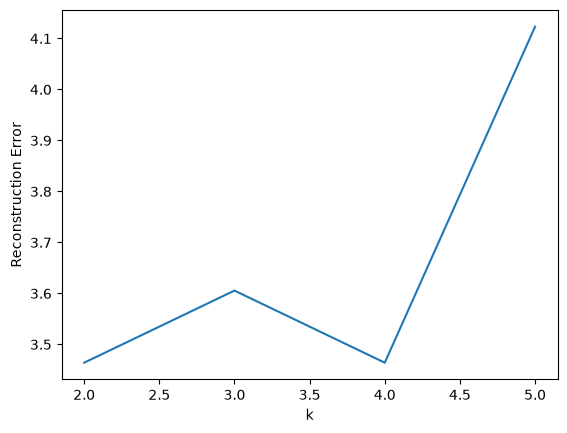

In [53]:
plt.plot(k_list, error_list)
plt.xlabel("k")
plt.ylabel("Reconstruction Error")
plt.show()